# 02 · Delta hedging: does the Black-Scholes price really pay for the hedge?

A market maker sells a 3-month at-the-money call to a client at the Black-Scholes price. They do **not** want to bet on the stock, so they **delta-hedge**: hold $\Delta$ shares against the short call and re-adjust as the price moves.

Black-Scholes promises that, under its assumptions, the premium exactly pays for this hedge and the final P&L is zero in every scenario. Real life breaks those assumptions, so we simulate 20,000 random price paths and measure what happens when:

| Experiment | What we change | Question |
|---|---|---|
| 1 | Rebalancing frequency | How much risk is left when you can only hedge weekly, daily, ...? |
| 2 | The stock's real drift $\mu$ | Does it matter if the stock tends to go up? |
| 3 | Realized volatility $\neq$ implied | What if you sold the option at the wrong vol? |
| 4 | Decompose daily P&L | Where exactly does the money come from? (gamma vs theta) |
| 5 | Transaction costs | What is the best hedging frequency once trading costs money? |

**Setup:** $S_0 = K = 100$, $T = 0.25$ years (63 trading days), $r = 5\%$, implied vol $\sigma = 20\%$, real-world drift $\mu = 10\%$.

In [1]:
# --- Setup: works both locally and in Google Colab ---
import os, sys
IN_COLAB = "google.colab" in sys.modules
REPO_DIR = "/content/options-pricing-hedging-lab"
if IN_COLAB and not os.path.isdir(REPO_DIR):
    user = input("GitHub username that hosts this repo: ").strip()
    os.system(f"git clone -q https://github.com/{user}/options-pricing-hedging-lab.git {REPO_DIR}")
    if not os.path.isdir(REPO_DIR):
        raise RuntimeError(f"Could not clone github.com/{user}/options-pricing-hedging-lab - check the username and that the repo is public.")
if IN_COLAB:
    os.chdir(f"{REPO_DIR}/notebooks")
sys.path.insert(0, os.path.abspath("../src"))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from optionslab import *
from optionslab.plotting import use_style, save, SERIES, BLUE, ORANGE, AQUA, YELLOW, INK, INK_2, MUTED

use_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
S0, K, T, r, sigma = 100.0, 100.0, 0.25, 0.05, 0.20
mu = 0.10            # real-world expected return of the stock (NOT used in pricing)
N_PATHS = 20_000

premium = float(bs_price(S0, K, T, r, sigma, "call"))
print(f"Premium received for the call: {premium:.4f}")
print(f"Initial hedge: buy {float(bs_delta(S0, K, T, r, sigma)):.4f} shares per call sold")

Premium received for the call: 4.6150
Initial hedge: buy 0.5695 shares per call sold


## How the hedge works, step by step (one path)

At time 0 we receive the premium, buy $\Delta_0$ shares, and keep the rest in cash. Then every day:

1. The stock moves; cash earns interest.
2. Recompute delta at the new price and remaining time.
3. Buy or sell the difference in shares, paying from (or adding to) cash.

At expiry we settle the option and sell the shares. The code below is written as a plain loop so every step is visible; the library function `simulate_delta_hedge` does exactly the same thing for thousands of paths at once.

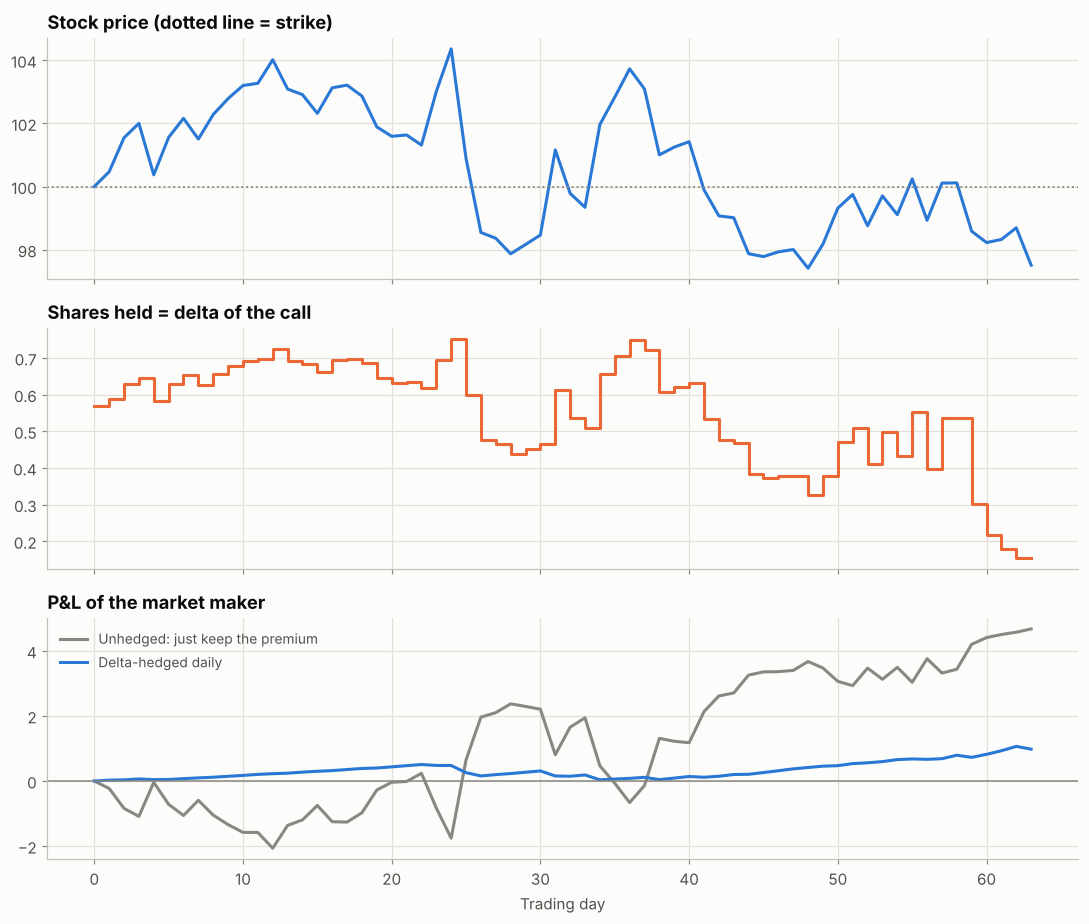

Final P&L on this path: unhedged +4.673, hedged +0.979


In [3]:
rng = np.random.default_rng(1)
n = 63                       # rebalance once per trading day
dt = T / n
t = np.arange(n + 1) * dt

S = np.empty(n + 1); S[0] = S0
for i in range(n):
    S[i + 1] = S[i] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * rng.standard_normal())

shares = np.empty(n + 1)
cash = np.empty(n + 1)
shares[0] = bs_delta(S0, K, T, r, sigma)
cash[0] = premium - shares[0] * S0                 # premium in, shares bought
for i in range(1, n + 1):
    cash_grown = cash[i - 1] * np.exp(r * dt)        # interest on cash
    target = bs_delta(S[i], K, T - t[i], r, sigma) if i < n else shares[i - 1]
    cash[i] = cash_grown - (target - shares[i - 1]) * S[i]
    shares[i] = target

option_value = bs_price(S, K, T - t, r, sigma)        # what we owe the client, marked to model
hedged_book = cash + shares * S - option_value       # P&L of (short call + shares + cash)
unhedged_book = premium * np.exp(r * t) - option_value

fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
axes[0].plot(t * 252, S, color=BLUE)
axes[0].axhline(K, color=MUTED, ls=":", lw=1.2)
axes[0].set_title("Stock price (dotted line = strike)")
axes[1].step(t * 252, shares, where="post", color=ORANGE)
axes[1].set_title("Shares held = delta of the call")
axes[2].plot(t * 252, unhedged_book, color=MUTED, label="Unhedged: just keep the premium")
axes[2].plot(t * 252, hedged_book, color=BLUE, label="Delta-hedged daily")
axes[2].axhline(0, color=MUTED, lw=1)
axes[2].set_title("P&L of the market maker")
axes[2].set_xlabel("Trading day"); axes[2].legend(loc="upper left")
fig.tight_layout()
save(fig, "08_single_path_hedge"); plt.show()
print(f"Final P&L on this path: unhedged {unhedged_book[-1]:+.3f}, hedged {hedged_book[-1]:+.3f}")

## Experiment 1 · How often do you need to hedge?

With continuous hedging the P&L would be exactly zero. With $N$ discrete rebalances, the stock moves between trades and the hedge is always slightly stale. The leftover error has mean $\approx 0$ and a standard deviation that shrinks like $1/\sqrt{N}$.

Derman and Kamal (1999) give a handy approximation for an at-the-money option:
$$\text{std(P\&L)} \approx \sqrt{\tfrac{\pi}{4}}\;\frac{\sigma \cdot \text{vega}}{\sqrt{N}}$$

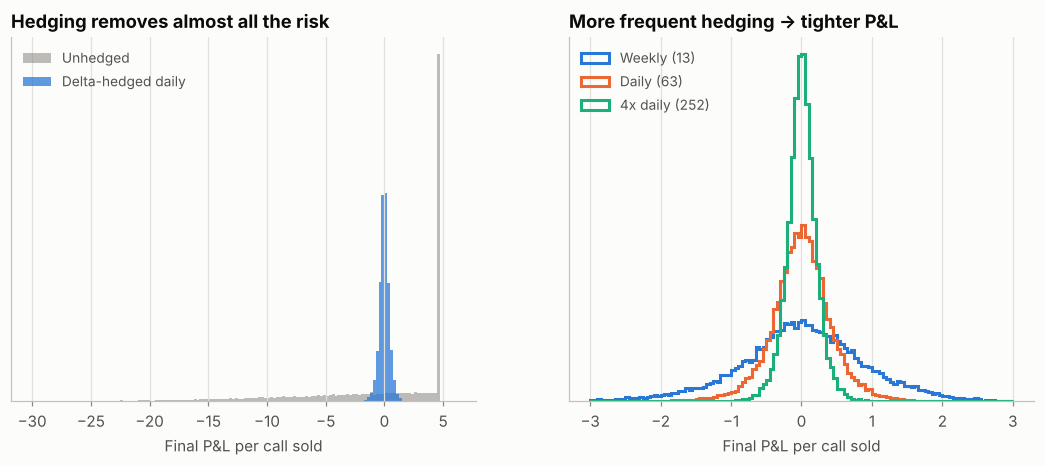

,rebalances,mean_pnl,std_pnl,std_pct_of_premium,p5,p95,mean_cost
Unhedged,0.0000,-0.7494,7.0366,152.4725,-15.1594,4.6150,0.0000
Weekly (13),13.0000,-0.0067,0.9214,19.9653,-1.5605,1.4855,0.0000
Daily (63),63.0000,-0.0063,0.4307,9.3327,-0.7119,0.6859,0.0000
4x daily (252),252.0000,-0.0017,0.2150,4.6595,-0.3532,0.3423,0.0000
16x daily (1008),"1,008.0000",-0.0006,0.1098,2.3799,-0.1788,0.1787,0.0000


In [4]:
schedules = {"Unhedged": 0, "Weekly (13)": 13, "Daily (63)": 63, "4x daily (252)": 252, "16x daily (1008)": 1008}
results = {name: simulate_delta_hedge(S0, K, T, r, sigma, mu=mu, n_rebalance=n, n_paths=N_PATHS, seed=2024)
           for name, n in schedules.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
bins = np.linspace(-30, 6, 145)
ax1.hist(results["Unhedged"].pnl, bins=bins, color=MUTED, alpha=0.55, label="Unhedged")
ax1.hist(results["Daily (63)"].pnl, bins=bins, color=BLUE, alpha=0.75, label="Delta-hedged daily")
ax1.set_title("Hedging removes almost all the risk")
ax1.set_xlabel("Final P&L per call sold"); ax1.set_yticks([]); ax1.legend(loc="upper left")

bins = np.linspace(-3, 3, 121)
for name, color in zip(["Weekly (13)", "Daily (63)", "4x daily (252)"], SERIES):
    ax2.hist(results[name].pnl, bins=bins, histtype="step", lw=2, color=color, label=name)
ax2.set_title("More frequent hedging -> tighter P&L")
ax2.set_xlabel("Final P&L per call sold"); ax2.set_yticks([]); ax2.legend(loc="upper left")
save(fig, "09_pnl_distributions"); plt.show()

summary = pd.DataFrame({name: res.summary() for name, res in results.items()}).T
summary

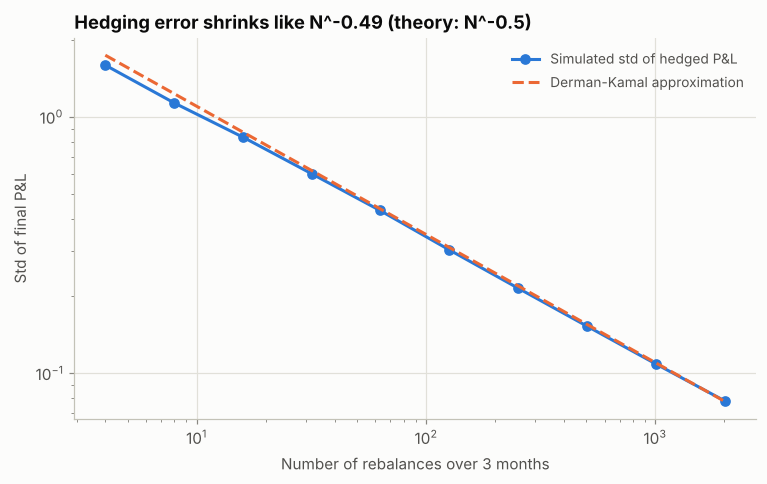

,rebalances,std P&L,Derman-Kamal,std as % of premium
0,4,1.5922,1.7409,34.5015
1,8,1.1333,1.2310,24.5570
2,16,0.8321,0.8705,18.0311
3,32,0.5982,0.6155,12.9610
4,63,0.4319,0.4387,9.3583
5,126,0.3035,0.3102,6.5757
6,252,0.2149,0.2193,4.6571
7,504,0.1527,0.1551,3.3090
8,1008,0.1087,0.1097,2.3544
9,2016,0.0779,0.0775,1.6878


In [5]:
Ns = [4, 8, 16, 32, 63, 126, 252, 504, 1008, 2016]
stds = np.array([simulate_delta_hedge(S0, K, T, r, sigma, mu=mu, n_rebalance=n, n_paths=N_PATHS, seed=n).std for n in Ns])
dk = np.array([derman_kamal_std(S0, K, T, r, sigma, n) for n in Ns])
slope = np.polyfit(np.log(Ns), np.log(stds), 1)[0]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(Ns, stds, "o-", color=BLUE, label="Simulated std of hedged P&L")
ax.loglog(Ns, dk, color=ORANGE, ls="--", label="Derman-Kamal approximation")
ax.set_xlabel("Number of rebalances over 3 months")
ax.set_ylabel("Std of final P&L")
ax.set_title(f"Hedging error shrinks like N^{slope:.2f} (theory: N^-0.5)")
ax.legend()
save(fig, "10_hedge_error_vs_frequency"); plt.show()

pd.DataFrame({"rebalances": Ns, "std P&L": stds, "Derman-Kamal": dk, "std as % of premium": 100 * stds / premium})

## Experiment 2 · The stock's drift does not matter

Intuition says a call should be worth more if the stock is expected to rise. Black-Scholes says no: $\mu$ is not in the formula. The reason is the hedge. The delta-hedged position has no exposure to the *direction* of the stock, only to its *volatility*. So the price that makes the hedge break even cannot depend on $\mu$.

This is the justification for **risk-neutral pricing** used in notebook 01 (simulate with drift $r$ instead of $\mu$). Below: unhedged P&L depends strongly on $\mu$; hedged P&L does not.

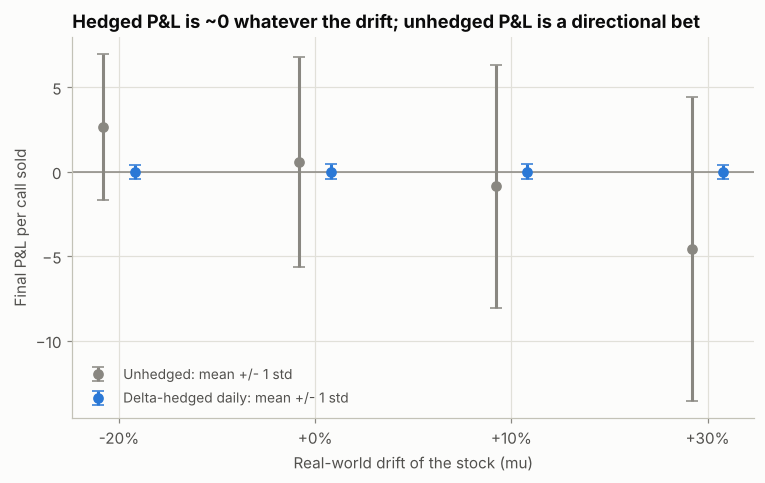

,drift mu,unhedged mean,unhedged std,hedged mean,hedged std
0,-0.2000,2.6365,4.3032,-0.0116,0.4186
1,0.0000,0.5708,6.2156,0.0002,0.4325
2,0.1000,-0.8724,7.1888,-0.0010,0.4280
3,0.3000,-4.5697,9.0003,-0.0127,0.4042


In [6]:
mus = [-0.20, 0.0, 0.10, 0.30]
rows = []
for m in mus:
    naked = simulate_delta_hedge(S0, K, T, r, sigma, mu=m, n_rebalance=0, n_paths=N_PATHS, seed=5)
    hedged = simulate_delta_hedge(S0, K, T, r, sigma, mu=m, n_rebalance=63, n_paths=N_PATHS, seed=5)
    rows.append({"drift mu": m, "unhedged mean": naked.mean, "unhedged std": naked.std,
                 "hedged mean": hedged.mean, "hedged std": hedged.std})
drift = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(mus))
ax.errorbar(x - 0.08, drift["unhedged mean"], yerr=drift["unhedged std"], fmt="o", color=MUTED,
            capsize=4, lw=2, label="Unhedged: mean +/- 1 std")
ax.errorbar(x + 0.08, drift["hedged mean"], yerr=drift["hedged std"], fmt="o", color=BLUE,
            capsize=4, lw=2, label="Delta-hedged daily: mean +/- 1 std")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x, [f"{m:+.0%}" for m in mus])
ax.set_xlabel("Real-world drift of the stock (mu)")
ax.set_ylabel("Final P&L per call sold")
ax.set_title("Hedged P&L is ~0 whatever the drift; unhedged P&L is a directional bet")
ax.legend(loc="lower left")
save(fig, "11_drift_independence"); plt.show()
drift

## Experiment 3 · Selling at the wrong volatility

Volatility is the one Black-Scholes input you cannot observe. A market maker *sells* at the **implied** vol $\sigma_i$ (20% here) but the stock then moves with some **realized** vol $\sigma_r$. If $\sigma_r > \sigma_i$, the stock moves more than the premium paid for, and the short-option hedger loses.

Theory (continuous hedging):
* **Hedge using the realized vol** in the delta: the P&L is locked in and equals the price difference $V(\sigma_i) - V(\sigma_r)$ on every path.
* **Hedge using the implied vol** (realistic: you do not know $\sigma_r$ in advance): almost the same average, but the P&L becomes path-dependent,
$$\text{P\&L} \approx \tfrac{1}{2}\int_0^T e^{-rt}\,\Gamma_t S_t^2\big(\sigma_i^2 - \sigma_r^2\big)\,dt,$$
so it depends on how much time the stock spends near the strike, where gamma is large.

This is the core of **volatility trading**: an options desk is effectively betting that realized vol will come in below the implied vol it sold at.

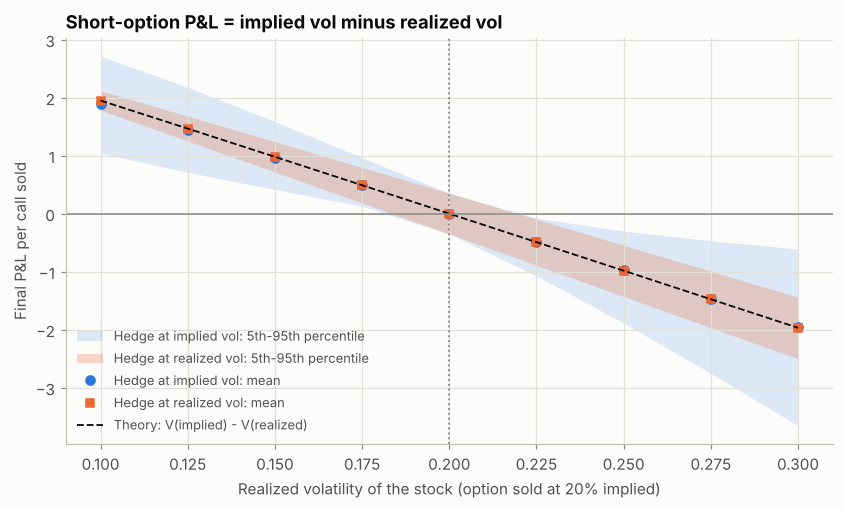

,realized vol,theory V(si) - V(sr),hedge @ implied: mean,hedge @ implied: std,hedge @ realized: mean,hedge @ realized: std
0,0.1000,1.9502,1.8972,0.5209,1.9507,0.1030
1,0.1250,1.4670,1.4379,0.4545,1.4677,0.1318
2,0.1500,0.9799,0.9662,0.3596,0.9813,0.1599
3,0.1750,0.4906,0.4865,0.2573,0.4924,0.1877
4,0.2000,0.0000,0.0019,0.2154,0.0019,0.2154
5,0.2250,-0.4914,-0.4859,0.3122,-0.4895,0.2430
6,0.2500,-0.9834,-0.9758,0.4936,-0.9815,0.2702
7,0.2750,-1.4757,-1.4669,0.7116,-1.4736,0.2975
8,0.3000,-1.9681,-1.9588,0.9506,-1.9657,0.3245


In [7]:
realized = np.round(np.arange(0.10, 0.301, 0.025), 3)
rows = []
for s_r in realized:
    at_implied = simulate_delta_hedge(S0, K, T, r, sigma, sigma_realized=s_r, mu=mu, n_rebalance=252, n_paths=N_PATHS, seed=3)
    at_realized = simulate_delta_hedge(S0, K, T, r, sigma, sigma_realized=s_r, mu=mu, hedge_vol=s_r, n_rebalance=252, n_paths=N_PATHS, seed=3)
    rows.append({
        "realized vol": s_r,
        "theory V(si) - V(sr)": premium - float(bs_price(S0, K, T, r, s_r)),
        "hedge @ implied: mean": at_implied.mean, "hedge @ implied: std": at_implied.std,
        "hedge @ realized: mean": at_realized.mean, "hedge @ realized: std": at_realized.std,
        "imp p5": np.percentile(at_implied.pnl, 5), "imp p95": np.percentile(at_implied.pnl, 95),
        "real p5": np.percentile(at_realized.pnl, 5), "real p95": np.percentile(at_realized.pnl, 95),
    })
vol = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.fill_between(vol["realized vol"], vol["imp p5"], vol["imp p95"], color=BLUE, alpha=0.15, lw=0,
                label="Hedge at implied vol: 5th-95th percentile")
ax.fill_between(vol["realized vol"], vol["real p5"], vol["real p95"], color=ORANGE, alpha=0.25, lw=0,
                label="Hedge at realized vol: 5th-95th percentile")
ax.plot(vol["realized vol"], vol["hedge @ implied: mean"], "o", color=BLUE, label="Hedge at implied vol: mean")
ax.plot(vol["realized vol"], vol["hedge @ realized: mean"], "s", color=ORANGE, ms=5, label="Hedge at realized vol: mean")
ax.plot(vol["realized vol"], vol["theory V(si) - V(sr)"], color=INK, lw=1.2, ls="--", label="Theory: V(implied) - V(realized)")
ax.axvline(sigma, color=MUTED, ls=":", lw=1.2)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("Realized volatility of the stock (option sold at 20% implied)")
ax.set_ylabel("Final P&L per call sold")
ax.set_title("Short-option P&L = implied vol minus realized vol")
ax.legend(loc="lower left", fontsize=8.5)
save(fig, "12_vol_mismatch"); plt.show()
vol[["realized vol", "theory V(si) - V(sr)", "hedge @ implied: mean", "hedge @ implied: std",
     "hedge @ realized: mean", "hedge @ realized: std"]]

## Experiment 4 · Where the P&L comes from: gamma versus theta

Expand the hedged portfolio's value over one small step $\delta t$ and use the Black-Scholes PDE. For a **short** option hedged at vol $\sigma$:

$$\delta\text{P\&L} \approx \underbrace{-\tfrac{1}{2}\Gamma\,(\delta S)^2}_{\text{gamma: big moves cost you}} \;+\; \underbrace{\tfrac{1}{2}\sigma^2 S^2\,\Gamma\,\delta t}_{\text{theta: time decay pays you}} \;=\; -\tfrac{1}{2}\Gamma S^2\left[\Big(\tfrac{\delta S}{S}\Big)^2 - \sigma^2\,\delta t\right]$$

Each day is a race: if today's squared return beats $\sigma^2\delta t$ (the variance the option price "expected"), the option seller loses; otherwise they win. Long-option traders run the mirror image, called **gamma scalping**. Below we check that this two-term formula explains the simulated P&L.

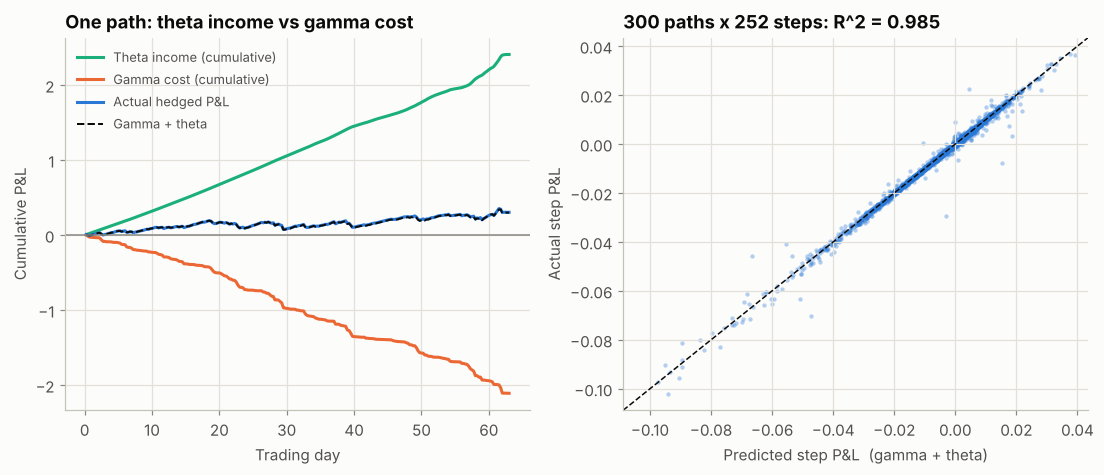

Two-term formula explains 98.5% of the variance of step-by-step hedged P&L


In [8]:
n_att = 252
att_paths = simulate_gbm_paths(S0, mu, sigma, T, n_steps=n_att, n_paths=300, seed=11)
one = hedge_pnl_attribution(att_paths[0], K, T, r, sigma)
all_steps = [hedge_pnl_attribution(p, K, T, r, sigma) for p in att_paths]
actual = np.concatenate([a["actual"] for a in all_steps])
predicted = np.concatenate([a["gamma"] + a["theta"] for a in all_steps])
r2 = 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - actual.mean()) ** 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
days = one["t"] * 252
ax1.plot(days, np.cumsum(one["theta"]), color=AQUA, label="Theta income (cumulative)")
ax1.plot(days, np.cumsum(one["gamma"]), color=ORANGE, label="Gamma cost (cumulative)")
ax1.plot(days, np.cumsum(one["actual"]), color=BLUE, label="Actual hedged P&L")
ax1.plot(days, np.cumsum(one["gamma"] + one["theta"]), color=INK, ls="--", lw=1.3, label="Gamma + theta")
ax1.axhline(0, color=MUTED, lw=1)
ax1.set_xlabel("Trading day"); ax1.set_ylabel("Cumulative P&L")
ax1.set_title("One path: theta income vs gamma cost")
ax1.legend(loc="upper left", fontsize=8.5)

idx = np.random.default_rng(0).choice(len(actual), size=6000, replace=False)
ax2.scatter(predicted[idx], actual[idx], s=8, color=BLUE, alpha=0.35, lw=0)
lim = np.percentile(np.abs(np.r_[actual, predicted]), 99.9)
ax2.plot([-lim, lim], [-lim, lim], color=INK, lw=1, ls="--")
ax2.set_xlim(-lim, lim * 0.4); ax2.set_ylim(-lim, lim * 0.4)
ax2.set_xlabel("Predicted step P&L  (gamma + theta)")
ax2.set_ylabel("Actual step P&L")
ax2.set_title(f"300 paths x 252 steps: R^2 = {r2:.3f}")
save(fig, "13_gamma_theta_attribution"); plt.show()
print(f"Two-term formula explains {100 * r2:.1f}% of the variance of step-by-step hedged P&L")

## Experiment 5 · Transaction costs: how often *should* you hedge?

Every rebalance costs money (bid-ask spread, fees). Here each trade costs **5 basis points** (0.05%) of the traded value. More frequent hedging lowers the hedging error ($\propto 1/\sqrt{N}$) but the total cost grows ($\propto \sqrt{N}$, Leland 1985), so there is a sweet spot. We use a simple objective: expected cost + one standard deviation of P&L.

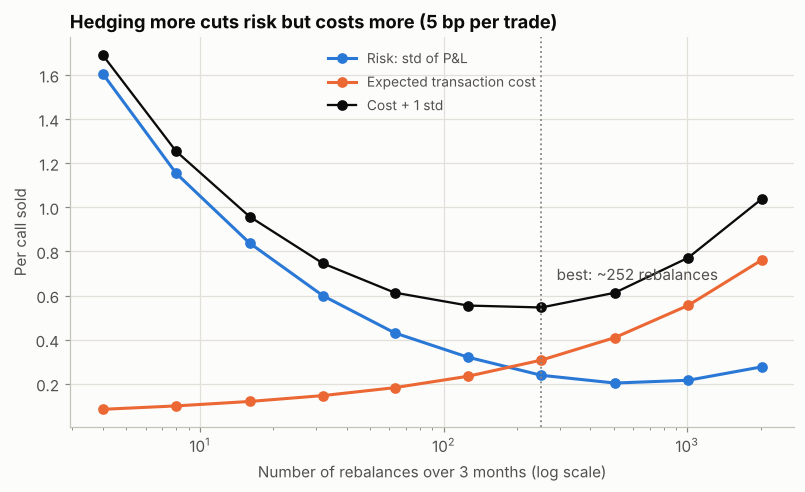

,rebalances,expected cost,std of P&L,mean P&L,cost + 1 std
0,4,0.0844,1.6060,-0.1194,1.6903
1,8,0.0998,1.1543,-0.1135,1.2541
2,16,0.1199,0.8384,-0.1286,0.9583
3,32,0.1465,0.5995,-0.1503,0.7460
4,63,0.1825,0.4310,-0.1826,0.6134
5,126,0.2343,0.3206,-0.2341,0.5549
6,252,0.3075,0.2386,-0.3072,0.5461
7,504,0.4094,0.2035,-0.4076,0.6129
8,1008,0.5554,0.2161,-0.5540,0.7715
9,2016,0.7607,0.2767,-0.7606,1.0374


In [9]:
cost_rate = 0.0005
Ns = [4, 8, 16, 32, 63, 126, 252, 504, 1008, 2016]
rows = []
for n_reb in Ns:
    res = simulate_delta_hedge(S0, K, T, r, sigma, mu=mu, n_rebalance=n_reb, n_paths=N_PATHS, cost_rate=cost_rate, seed=9)
    rows.append({"rebalances": n_reb, "expected cost": res.costs.mean(), "std of P&L": res.std,
                 "mean P&L": res.mean})
tc = pd.DataFrame(rows)
tc["cost + 1 std"] = tc["expected cost"] + tc["std of P&L"]
best = tc.loc[tc["cost + 1 std"].idxmin()]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(tc.rebalances, tc["std of P&L"], "o-", color=BLUE, label="Risk: std of P&L")
ax.plot(tc.rebalances, tc["expected cost"], "o-", color=ORANGE, label="Expected transaction cost")
ax.plot(tc.rebalances, tc["cost + 1 std"], "o-", color=INK, lw=1.5, label="Cost + 1 std")
ax.axvline(best.rebalances, color=MUTED, ls=":", lw=1.2)
ax.annotate(f"best: ~{int(best.rebalances)} rebalances", (best.rebalances, best["cost + 1 std"]),
            xytext=(10, 18), textcoords="offset points", color=INK_2)
ax.set_xscale("log")
ax.set_xlabel("Number of rebalances over 3 months (log scale)")
ax.set_ylabel("Per call sold")
ax.set_title("Hedging more cuts risk but costs more (5 bp per trade)")
ax.legend(loc="upper center")
save(fig, "14_transaction_costs"); plt.show()
tc

## Takeaways

1. **Delta hedging works.** Daily hedging cuts the P&L standard deviation about 16x (from 7.04 to 0.43 per call) compared with leaving the short call naked.
2. **Discrete hedging leaves a residual error** that shrinks like $1/\sqrt{N}$, matching the Derman-Kamal formula.
3. **The drift $\mu$ is irrelevant once hedged**, which is why options are priced under the risk-neutral measure.
4. **The real risk is volatility.** Selling at 20% implied when 25% is realized loses about 1 point per option; the average loss matches $V(\sigma_i) - V(\sigma_r)$.
5. **Daily P&L = gamma cost + theta income**, explaining about 98.5% of the variance of step-by-step P&L.
6. **Transaction costs create an optimal hedging frequency**; hedging "as often as possible" is not optimal.

**Limitations (honest list):** constant volatility and lognormal returns (real markets have jumps, fat tails and stochastic vol), no bid-ask on the option itself, the same rate for borrowing and lending, and no market impact. Notebook 03 shows that real markets do not even agree on a single volatility.